# audiollm: from data to LLM tokens, step by step

This notebook walks through the pipeline in [`train.py`](train.py) and **reuses its functions**, so what you see here
is exactly what the training loop gets:

1. **The data**: LibriSpeech splits on disk, durations, a sample utterance
2. **How it is split**: train / val / test selection, and how utterances are grouped into batches
3. **How audio goes into the model**: wav → STFT → mel → log → MVN → pad → stack `STACK` frames = 1 "patch"
4. **The adapter**: the layer that turns a `STACK × N_MELS` audio patch into a `d_model` LLM token (plus the trained
   weights), and how the patch size compares to the LLM width
   (4b: a side-by-side sweep of whole front-end configs `SR / N_FFT / HOP / N_MELS / STACK`)
5. **The final input sequence**: `[BOS][audio…]["Transcription:"][text][EOS]`, padding, attention mask, labels
6. *(optional)* a forward pass + greedy decode with the trained checkpoint, and where LoRA sits in the LLM
7. **Run tracking**: `runs/latest`, `runs/INDEX.md`, the per-run `plots.png`

```
wav ─► N_MELS-d log-mel (N_FFT win / HOP hop) ─► MVN ─► stack STACK frames = 1 patch (STACK·N_MELS-d)
    ─► Linear(STACK·N_MELS → d_model) ─► [BOS][audio…]["Transcription:"][ text ][EOS] ─► LFM2.5 (frozen) + LoRA
```
(defaults: 80 mels, 25 ms / 10 ms, STACK = 16 → 1280-d patches at 6.25 Hz; STACK = 8 → 640-d at 12.5 Hz is the paper's
rate. Trained: the `Linear` projector (fully) and LoRA adapters on the LLM's linear layers; the LLM weights stay frozen.)

**Every knob is in the `PARAMETERS` block of the first code cell**: edit it, then *Run All*.
The LLM parts run on the **GPU** (`DEVICE = "auto"`, bf16 like training); set `DEVICE = "cpu"` if a training run needs the whole GPU. Feature extraction and the plots are always on CPU.


## 0. Setup and parameters

`OVERRIDES` accepts any UPPERCASE constant of `train.py` (same names as its CLI flags, upper-cased), so the notebook shows
exactly what `python train.py --stack 16 ...` would feed the model. A trained run is only reused if it was trained with
the same patch shape (`MODEL`, `SR`, `N_FFT`, `HOP`, `N_MELS`, `STACK`); otherwise the adapter is randomly initialised.


In [1]:
import json, os, random, sys
from collections import Counter
from pathlib import Path

# train.py uses paths relative to the repo root (data/LibriSpeech, runs/...)
ROOT = Path.cwd()
while not (ROOT / "train.py").exists():
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np
import torch
import matplotlib.pyplot as plt
import soundfile as sf
from IPython.display import Audio, display
from transformers import AutoConfig

import train as T   # the training script: all functions + config constants (MODEL = LFM2.5-230M-Base)

# ═══════════════════════════ PARAMETERS: edit, then Run All ═══════════════════════════
OVERRIDES = {
    # "STACK": 16,       # frames per patch: 8 -> 640-d @ 12.5 Hz, 16 -> 1280-d @ 6.25 Hz (230M hidden_size = 1024)
    # "N_MELS": 128,     # mel bins per frame (MVN stats for a new value are computed + cached in section 3c, ~1 min)
    # "HOP": 160, "N_FFT": 400,
    # "MODEL": "LiquidAI/LFM2.5-1.2B-Base",
}
USE_TRAINED_RUN = True                     # reuse the newest finished run with the same patch shape (if any)
SAMPLE_INDEX = 42                          # train-clean-100 utterance walked through in sections 1 and 3
STACK_SWEEP = [4, 6, 8, 10, 12, 16, 20, 24, 32]   # patch sizes compared against the LLM width in section 4
FRONTEND_SWEEP = [                         # front-end configs compared side by side in section 4b (missing keys = current value)
    {},                                    # the current config
    {"STACK": 8},                          # paper rate: 12.5 Hz tokens, 640-d patches
    {"N_MELS": 128},                       # finer frequency resolution, 2048-d patches
    {"N_MELS": 40, "STACK": 32},           # coarse frequency, same 1280-d patch, 3.1 Hz tokens
    {"N_FFT": 512},                        # 32 ms window: finer FFT bins, blurrier onsets
    {"HOP": 320, "N_FFT": 640, "STACK": 8},  # 20 ms frames, same 160 ms per token as STACK=16
    {"SR": 8000, "N_FFT": 200, "HOP": 80},   # telephone band (drops everything above 4 kHz)
]
FRONTEND_PROBE_N = 200                     # train utterances each config in section 4b is measured on
DEVICE = "auto"                            # "auto" = GPU if available (ROCm: the AMD GPU is "cuda"), "cuda", "cpu"
# ════════════════════════════════════════════════════════════════════════════════════════

unknown = [k for k in OVERRIDES if k not in T.DEFAULT_CONFIG]
assert not unknown, f"not train.py constants: {unknown}"
T.apply_config(OVERRIDES)

# A checkpoint is only reusable if everything that defines a patch matches
SHAPE_KEYS = ["MODEL", "SR", "N_FFT", "HOP", "N_MELS", "STACK"]
wanted = {k: getattr(T, k) for k in SHAPE_KEYS}
RUN_DIR = None
if USE_TRAINED_RUN:
    finished = sorted(Path("runs").glob("*/proj.pt"), key=lambda p: p.stat().st_mtime, reverse=True)
    for proj_file in finished:
        run_cfg = json.load(open(proj_file.parent / "config.json"))
        if all(run_cfg.get(k) == v for k, v in wanted.items()):
            RUN_DIR = proj_file.parent
            run_cfg.setdefault("PRECISION", "fp32")   # runs from before PRECISION existed
            T.apply_config({**run_cfg, **OVERRIDES})  # the run's config, explicit overrides still win
            break
print("trained run:", RUN_DIR or f"none with {wanted} (adapter will be randomly initialised)")

# Notebook device: GPU -> bf16 like training; CPU -> fp32 (CPU bf16 is slow)
if DEVICE == "auto":
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
T.DEVICE, T.DTYPE = DEVICE, (torch.float32 if DEVICE == "cpu" else torch.bfloat16)
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "", "| dtype:", T.DTYPE)
torch.set_num_threads(4)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})

FPS = T.SR / T.HOP                  # mel frames per second
PATCH_DIM = T.STACK * T.N_MELS      # input size of the adapter
H = AutoConfig.from_pretrained(T.MODEL).hidden_size
changed = {k: getattr(T, k) for k in T.DEFAULT_CONFIG if k != "DTYPE" and getattr(T, k) != T.DEFAULT_CONFIG[k]}
print("differs from train.py defaults:", changed or "nothing")
print(f"MODEL={T.MODEL}  SR={T.SR}  N_FFT={T.N_FFT}  HOP={T.HOP}  N_MELS={T.N_MELS}  STACK={T.STACK}")
print(f"frame rate = {FPS:.0f} Hz, audio token rate = {FPS / T.STACK:.2f} Hz ({1000 * T.STACK / FPS:.0f} ms/token), "
      f"patch dim = {T.STACK} x {T.N_MELS} = {PATCH_DIM} -> hidden_size {H} ({PATCH_DIM / H:.2f}x)")


(null): No such file or directory
/home/nguyenlt/Programming/audiollm/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


trained run: runs/20261027-142314_fix_matchemb_plr10_ponly300_smoke1500
device: cuda AMD Radeon Graphics | dtype: torch.bfloat16


(null): No such file or directory


differs from train.py defaults: {'RUN_NAME': 'fix_matchemb_plr10_ponly300', 'TRAIN_SPLIT': 'train-clean-100', 'EVAL_AUDIO_ABLATIONS': 'shuffle', 'PROJ_LR_MULT': 10.0, 'PROJ_ONLY_STEPS': 300, 'EPOCHS': 10, 'EVAL_EVERY': 250, 'MAX_NEW_TOKENS': 200, 'PRECISION': 'amp'}
MODEL=LiquidAI/LFM2.5-230M-Base  SR=16000  N_FFT=400  HOP=160  N_MELS=80  STACK=16
frame rate = 100 Hz, audio token rate = 6.25 Hz (160 ms/token), patch dim = 16 x 80 = 1280 -> hidden_size 1024 (1.25x)


## 1. The data

`prepare_data.py` unpacks LibriSpeech into the standard OpenSLR layout:
`data/LibriSpeech/<split>/<speaker>/<chapter>/<utt-id>.flac` + one `<speaker>-<chapter>.trans.txt` per chapter.
`T.load_librispeech_split()` scans that and returns one dict per utterance: `id, path, text, sec`.

In [2]:
!find data/LibriSpeech/train-clean-100 -maxdepth 3 | head -8
first_trans = sorted(Path("data/LibriSpeech/train-clean-100").rglob("*.trans.txt"))[0]
print("\n", first_trans); print("".join(first_trans.read_text().splitlines(True)[:3]))

data/LibriSpeech/train-clean-100
data/LibriSpeech/train-clean-100/374
data/LibriSpeech/train-clean-100/374/180298
data/LibriSpeech/train-clean-100/374/180298/374-180298-0000.flac
data/LibriSpeech/train-clean-100/374/180298/374-180298-0001.flac
data/LibriSpeech/train-clean-100/374/180298/374-180298-0002.flac
data/LibriSpeech/train-clean-100/374/180298/374-180298-0003.flac
data/LibriSpeech/train-clean-100/374/180298/374-180298-0004.flac

 data/LibriSpeech/train-clean-100/103/1240/103-1240.trans.txt
103-1240-0000 CHAPTER ONE MISSUS RACHEL LYNDE IS SURPRISED MISSUS RACHEL LYNDE LIVED JUST WHERE THE AVONLEA MAIN ROAD DIPPED DOWN INTO A LITTLE HOLLOW FRINGED WITH ALDERS AND LADIES EARDROPS AND TRAVERSED BY A BROOK
103-1240-0001 THAT HAD ITS SOURCE AWAY BACK IN THE WOODS OF THE OLD CUTHBERT PLACE IT WAS REPUTED TO BE AN INTRICATE HEADLONG BROOK IN ITS EARLIER COURSE THROUGH THOSE WOODS WITH DARK SECRETS OF POOL AND CASCADE BUT BY THE TIME IT REACHED LYNDE'S HOLLOW IT WAS A QUIET WELL CONDUCTE

In [3]:
# Scanning reads every file header (sf.info) -> ~30 s for train-clean-100
splits = {name: T.load_librispeech_split(name) for name in [T.TRAIN_SPLIT, T.VAL_SPLIT, *T.TEST_SPLITS]}

def speaker(item): return item["id"].split("-")[0]

print(f"{'split':<17}{'utts':>7}{'hours':>8}{'speakers':>10}{'mean s':>8}{'max s':>7}{'words/utt':>11}")
for name, items in splits.items():
    secs = np.array([it["sec"] for it in items])
    words = np.mean([len(it["text"].split()) for it in items])
    print(f"{name:<17}{len(items):>7}{secs.sum() / 3600:>8.1f}{len({speaker(it) for it in items}):>10}"
          f"{secs.mean():>8.1f}{secs.max():>7.1f}{words:>11.1f}")

split               utts   hours  speakers  mean s  max s  words/utt
train-clean-100    28539   100.6       251    12.7   24.5       34.7
dev-clean           2703     5.4        40     7.2   32.6       20.1
test-clean          2620     5.4        40     7.4   35.0       20.1
test-other          2939     5.3        33     6.5   34.5       17.8


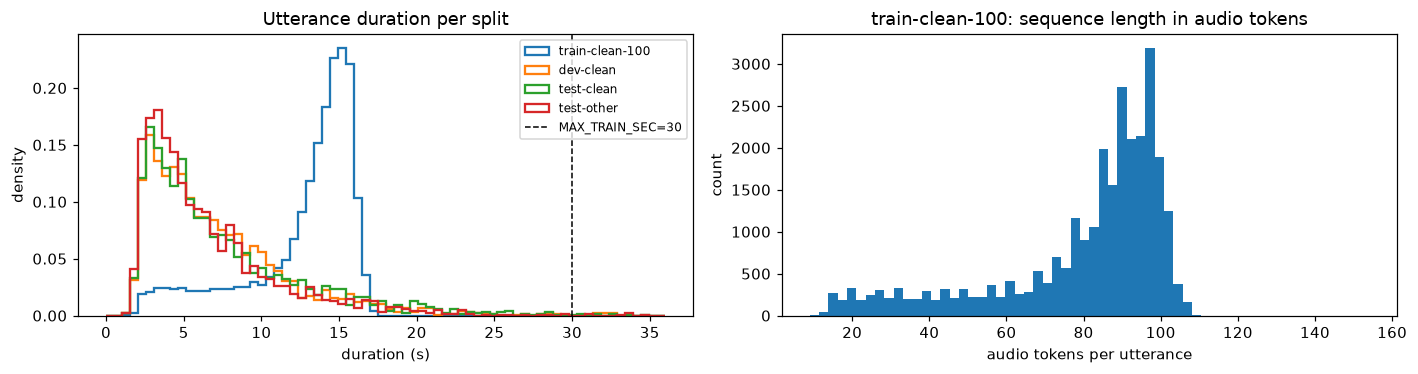

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for name, items in splits.items():
    axes[0].hist([it["sec"] for it in items], bins=70, range=(0, 36), histtype="step", density=True, lw=1.5, label=name)
axes[0].axvline(T.MAX_TRAIN_SEC, color="k", ls="--", lw=1, label=f"MAX_TRAIN_SEC={T.MAX_TRAIN_SEC:.0f}")
axes[0].set(xlabel="duration (s)", ylabel="density", title="Utterance duration per split"); axes[0].legend(fontsize=8)

train_secs = np.array([it["sec"] for it in splits[T.TRAIN_SPLIT]])
n_tokens = np.ceil(train_secs * T.SR / T.HOP / T.STACK)   # ~ audio tokens the LLM sees per utterance
axes[1].hist(n_tokens, bins=60, color="C0")
axes[1].set(xlabel="audio tokens per utterance", ylabel="count", title=f"{T.TRAIN_SPLIT}: sequence length in audio tokens")
plt.tight_layout(); plt.show()

### A sample utterance

103-1240-0042 | 15.61 s | 249680 samples @ 16000 Hz
text: so in the end we decided to ask missus spencer to pick us out one when she went over to get her little girl we heard last week she was going so we sent her word by richard spencer's folks at carmody to bring us a smart likely boy of about ten or eleven we decided that would be the best age


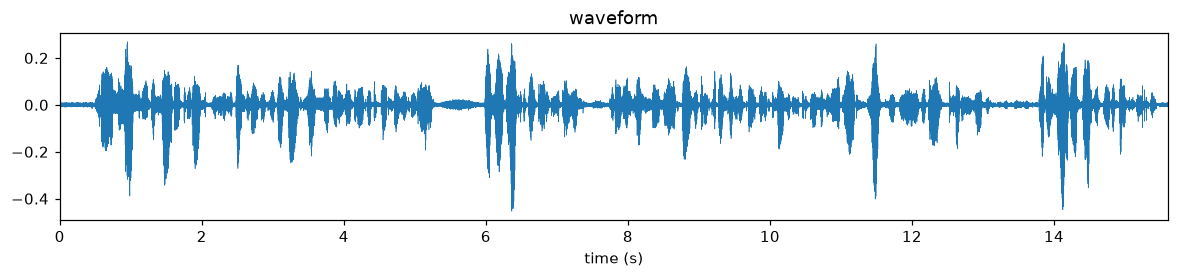

In [5]:
sample = splits[T.TRAIN_SPLIT][SAMPLE_INDEX]
wav, sr = sf.read(sample["path"], dtype="float32")
print(sample["id"], f"| {sample['sec']:.2f} s | {len(wav)} samples @ {sr} Hz")
print("text:", sample["text"])
display(Audio(wav, rate=sr))

t = np.arange(len(wav)) / sr
plt.figure(figsize=(13, 2.2)); plt.plot(t, wav, lw=0.4)
plt.xlim(0, t[-1]); plt.xlabel("time (s)"); plt.title("waveform"); plt.show()

## 2. How the data is split

| role | source | rule (in `train.train()`) |
|---|---|---|
| **train** | `train-clean-100` | all utterances with `sec <= MAX_TRAIN_SEC` |
| **val** (in-training WER) | `dev-clean` | first `VAL_N` utterances **sorted by id**: fixed and deterministic |
| **test** | `test-clean`, `test-other` | everything, only used at the end (`train.py`'s own `[a-z' ]` WER) |
| **benchmark** | Open ASR sets: LibriSpeech clean/other, VoxPopuli, AMI, Earnings-22, GigaSpeech, SPGISpeech | test splits only, run by `benchmark.py` after training (Whisper normaliser) |

**Only LibriSpeech is used for training and model selection.** All training data is `train-clean-100` (100.6 h,
251 speakers, read audiobooks), and its only dev split is `dev-clean`. `dev-other` and the other LibriSpeech train
splits are not downloaded (`prepare_data.py`). The non-LibriSpeech benchmark sets have **no training data and no
dev split** here (we only download their test sets), so on those the model is zero-shot and out of domain:
parliament speech, meetings, earnings calls, podcasts/YouTube, and finance calls (Earnings-22 audio is also not 16 kHz;
`benchmark.read_wav` resamples it).

**The val subset is small and narrow.** The first `VAL_N=200` dev-clean utterances by id come from only **3 of the 40
dev-clean speakers** (8 chapters, ~23 min). It's fixed and deterministic, so curves are comparable across runs, but it
is a noisy estimate of dev-clean and says nothing about "other" or out-of-domain speech.

LibriSpeech splits are already speaker-disjoint; the cell below checks it.

In [6]:
train_items = [it for it in splits[T.TRAIN_SPLIT] if it["sec"] <= T.MAX_TRAIN_SEC]
val_items = sorted(splits[T.VAL_SPLIT], key=lambda it: it["id"])[:T.VAL_N]
dropped = len(splits[T.TRAIN_SPLIT]) - len(train_items)
print(f"train: {len(train_items)} utts ({sum(it['sec'] for it in train_items) / 3600:.1f} h), "
      f"dropped {dropped} longer than {T.MAX_TRAIN_SEC} s")
print(f"val  : {len(val_items)} utts ({sum(it['sec'] for it in val_items) / 60:.1f} min) from "
      f"{len({speaker(it) for it in val_items})} speakers: {val_items[0]['id']} .. {val_items[-1]['id']}")

spk = {name: {speaker(it) for it in items} for name, items in splits.items()}
names = list(spk)
for i, a in enumerate(names):
    for b in names[i + 1:]:
        print(f"speaker overlap {a:>16} & {b:<16}: {len(spk[a] & spk[b])}")

train: 28539 utts (100.6 h), dropped 0 longer than 30.0 s
val  : 200 utts (22.6 min) from 3 speakers: 1272-128104-0000 .. 1673-143397-0011
speaker overlap  train-clean-100 & dev-clean       : 0
speaker overlap  train-clean-100 & test-clean      : 0
speaker overlap  train-clean-100 & test-other      : 0
speaker overlap        dev-clean & test-clean      : 0
speaker overlap        dev-clean & test-other      : 0
speaker overlap       test-clean & test-other      : 0


### Batching: length-bucketed sampler

`T.create_length_batched_sampler()` (new seed each epoch):
1. shuffle all utterance indices
2. cut into chunks of `BATCH_SIZE * 50` and **sort each chunk by duration**
3. slice each sorted chunk into batches of `BATCH_SIZE`, then shuffle the batch order

So each batch holds utterances of similar length (little padding), while the order of batches stays random.
`GRAD_ACCUM` micro-batches make one optimizer step.

3568 micro-batches/epoch of 8 -> 892 optimizer steps/epoch (x4 accum = eff. batch 32), 8920 total
audio padding efficiency: bucketed 98.9% vs plain random 79.9%

first 3 batches (durations in s):
   [14.2, 14.2, 14.2, 14.2, 14.2, 14.2, 14.2, 14.2]
   [14.9, 14.9, 14.9, 15.0, 15.0, 15.0, 15.0, 15.0]
   [14.5, 14.5, 14.5, 14.5, 14.5, 14.5, 14.5, 14.6]


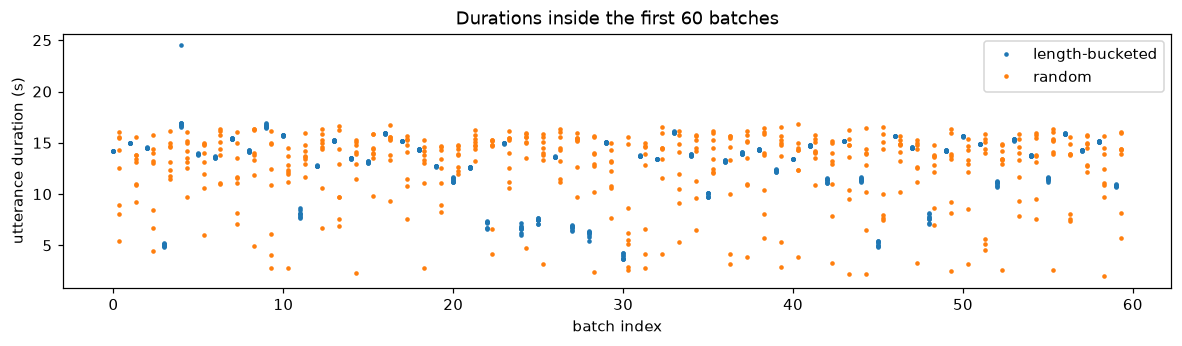

In [7]:
batches = T.create_length_batched_sampler(train_items, T.BATCH_SIZE, seed=T.SEED)
idx = list(range(len(train_items)))
random.Random(0).shuffle(idx)
random_batches = [idx[i:i + T.BATCH_SIZE] for i in range(0, len(idx), T.BATCH_SIZE)]

def pad_efficiency(bs):
    real = sum(train_items[i]["sec"] for b in bs for i in b)
    padded = sum(max(train_items[i]["sec"] for i in b) * len(b) for b in bs)
    return real / padded

steps_per_epoch = len(batches) // T.GRAD_ACCUM
print(f"{len(batches)} micro-batches/epoch of {T.BATCH_SIZE} -> {steps_per_epoch} optimizer steps/epoch "
      f"(x{T.GRAD_ACCUM} accum = eff. batch {T.BATCH_SIZE * T.GRAD_ACCUM}), {steps_per_epoch * T.EPOCHS} total")
print(f"audio padding efficiency: bucketed {pad_efficiency(batches):.1%} vs plain random {pad_efficiency(random_batches):.1%}")
print("\nfirst 3 batches (durations in s):")
for b in batches[:3]:
    print("  ", [round(train_items[i]["sec"], 1) for i in b])

fig, ax = plt.subplots(figsize=(13, 3))
for k, (bs, label) in enumerate([(batches, "length-bucketed"), (random_batches, "random")]):
    for j, b in enumerate(bs[:60]):
        d = [train_items[i]["sec"] for i in b]
        ax.plot([j + 0.3 * k] * len(d), d, ".", color=f"C{k}", ms=4, label=label if j == 0 else None)
ax.set(xlabel="batch index", ylabel="utterance duration (s)", title="Durations inside the first 60 batches")
ax.legend(); plt.show()

## 3. How the audio is put into the model

There is **no audio encoder**. Each step below is a line of `T.extract_log_mel_spectrogram()` (reads the file, then
`T.log_mel_from_waveform()`, which `benchmark.py` also uses on decoded/resampled audio) or
`T.SpeechDataset.__getitem__()`; here they are run one at a time so every intermediate can be plotted.

### 3a. STFT → power spectrogram
Window of `N_FFT=400` samples (25 ms), hop of `HOP=160` samples (10 ms) → **`SR / HOP` = 100 frames/s** with the defaults, `N_FFT/2+1 = 201` frequency bins.

waveform (249680,) -> STFT (201, 1561) (freq bins, frames)


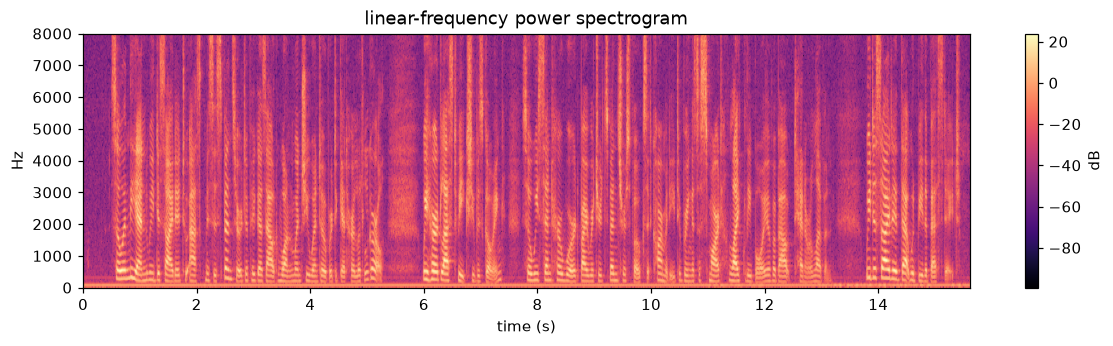

In [8]:
stft = torch.stft(torch.from_numpy(wav), n_fft=T.N_FFT, hop_length=T.HOP, window=T.STFT_WINDOW, return_complex=True)
power = stft.abs() ** 2
print("waveform", tuple(wav.shape), "-> STFT", tuple(stft.shape), "(freq bins, frames)")

plt.figure(figsize=(13, 3))
plt.imshow(10 * np.log10(power.numpy() + 1e-10), origin="lower", aspect="auto", cmap="magma",
           extent=[0, power.shape[1] / FPS, 0, T.SR / 2])
plt.colorbar(label="dB"); plt.xlabel("time (s)"); plt.ylabel("Hz"); plt.title("linear-frequency power spectrogram"); plt.show()

### 3b. Mel filterbank (HTK, 80 triangles) → log
`T.MEL_FILTERBANK` is an `(80, 201)` matrix: each row is a triangle on the linear-frequency axis,
narrow at low frequencies and wide at high frequencies. `log(filterbank @ power + 1e-6)` gives `(frames, 80)`.

filterbank (80, 201) | log-mel (1561, 80) (frames, mel bins)


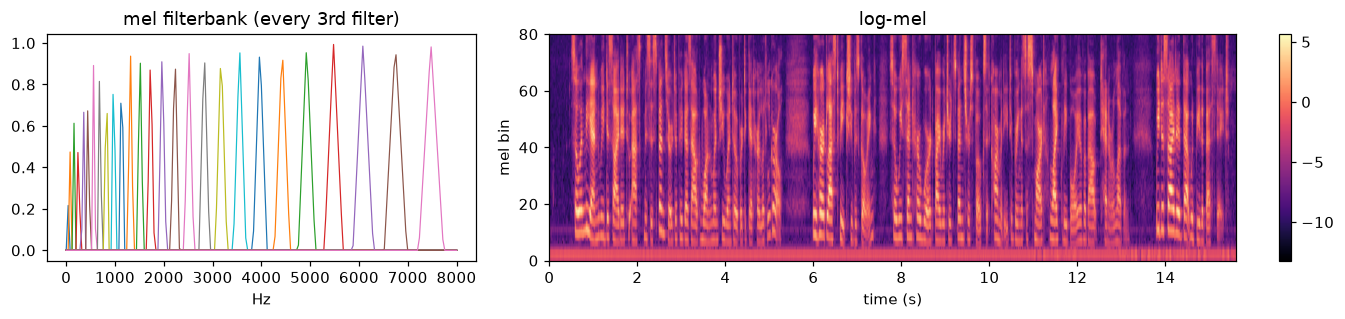

In [9]:
fb = T.MEL_FILTERBANK
freqs = np.fft.rfftfreq(T.N_FFT, 1 / T.SR)
log_mel = T.extract_log_mel_spectrogram(sample["path"])          # the function the Dataset uses
assert torch.allclose(log_mel, torch.log(fb @ power + 1e-6).T)   # == the manual steps above
print("filterbank", tuple(fb.shape), "| log-mel", tuple(log_mel.shape), "(frames, mel bins)")

fig, axes = plt.subplots(1, 2, figsize=(13, 3), gridspec_kw={"width_ratios": [1, 2]})
for m in range(0, T.N_MELS, 3):
    axes[0].plot(freqs, fb[m], lw=0.8)
axes[0].set(xlabel="Hz", title="mel filterbank (every 3rd filter)")
im = axes[1].imshow(log_mel.T, origin="lower", aspect="auto", cmap="magma", extent=[0, log_mel.shape[0] / FPS, 0, T.N_MELS])
axes[1].set(xlabel="time (s)", ylabel="mel bin", title="log-mel"); plt.colorbar(im, ax=axes[1])
plt.tight_layout(); plt.show()

### 3c. Global mean-variance normalisation (MVN)
One mean and std **per mel bin**, computed once from `MVN_N=2000` random train utterances and cached
(`data/LibriSpeech/mvn_train-clean-100_n2000.pt`). After MVN every bin is roughly zero-mean / unit-variance,
so **0 = "average frame"**, which is why the tail is padded with zeros next.

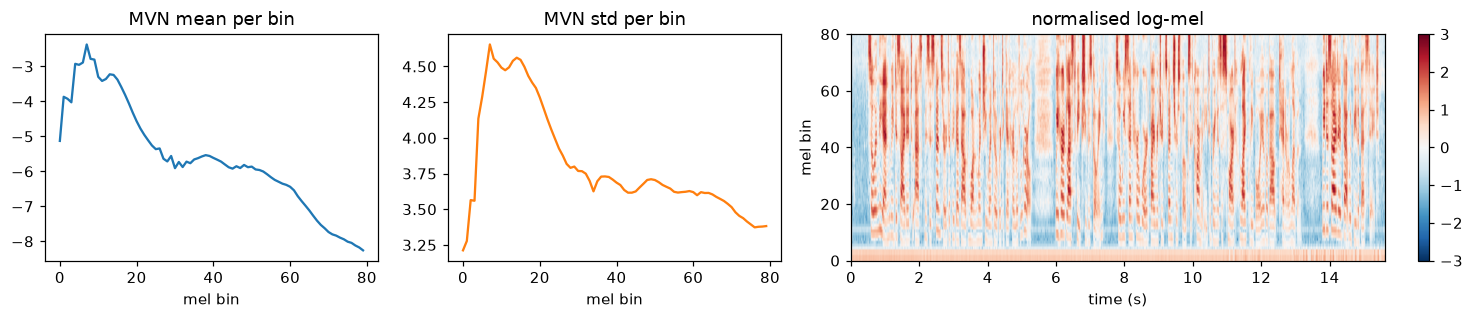

before MVN: mean -5.11 std 3.08 | after: mean 0.15 std 0.78


In [10]:
mvn = T.compute_or_load_mvn_stats(train_items)   # loads the cache
norm_mel = (log_mel - mvn["mean"]) / mvn["std"]

fig, axes = plt.subplots(1, 3, figsize=(14, 3), gridspec_kw={"width_ratios": [1, 1, 2]})
axes[0].plot(mvn["mean"]); axes[0].set(title="MVN mean per bin", xlabel="mel bin")
axes[1].plot(mvn["std"], color="C1"); axes[1].set(title="MVN std per bin", xlabel="mel bin")
im = axes[2].imshow(norm_mel.T, origin="lower", aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3,
                    extent=[0, norm_mel.shape[0] / FPS, 0, T.N_MELS])
axes[2].set(xlabel="time (s)", ylabel="mel bin", title="normalised log-mel"); plt.colorbar(im, ax=axes[2])
plt.tight_layout(); plt.show()
print(f"before MVN: mean {log_mel.mean():.2f} std {log_mel.std():.2f} | after: mean {norm_mel.mean():.2f} std {norm_mel.std():.2f}")

### 3d. Pad + stack `STACK` frames → one audio patch
The spectrogram is cut **only along time** into chunks of `STACK` frames (`STACK × HOP / SR` seconds), keeping all
`N_MELS` mel bins. Each `STACK × N_MELS` chunk is flattened row-major into a **`STACK·N_MELS`-d vector**:
`[frame0 bins 0..N_MELS-1, frame1 bins …, …]` (default 8 × 80 = 640-d, 80 ms).
The last chunk is zero-padded if the frame count isn't a multiple of `STACK`.


In [11]:
pad = (-norm_mel.shape[0]) % T.STACK
padded = torch.cat([norm_mel, norm_mel.new_zeros(pad, T.N_MELS)])
patches = padded.reshape(-1, T.STACK * T.N_MELS)
print(f"{norm_mel.shape[0]} frames + {pad} zero frames = {padded.shape[0]} -> patches {tuple(patches.shape)}")

# Same thing through the Dataset the training loop uses
tok = T.AutoTokenizer.from_pretrained(T.MODEL)
ds = T.SpeechDataset([sample], mvn, tok)
ex = ds[0]
assert torch.equal(ex["audio"], patches)
print("SpeechDataset item:", {k: (tuple(v.shape) if torch.is_tensor(v) else v if isinstance(v, str) else f"list[{len(v)}]")
                              for k, v in ex.items()})
# patch k, frame f, bin b  <->  padded[k*STACK + f, b]  <->  patches[k, f*N_MELS + b]
assert torch.equal(patches[5].view(T.STACK, T.N_MELS), padded[5 * T.STACK:6 * T.STACK])

1561 frames + 7 zero frames = 1568 -> patches (98, 1280)
SpeechDataset item: {'audio': (98, 1280), 'target': 'list[70]', 'text': "so in the end we decided to ask missus spencer to pick us out one when she went over to get her little girl we heard last week she was going so we sent her word by richard spencer's folks at carmody to bring us a smart likely boy of about ten or eleven we decided that would be the best age", 'id': '103-1240-0042'}


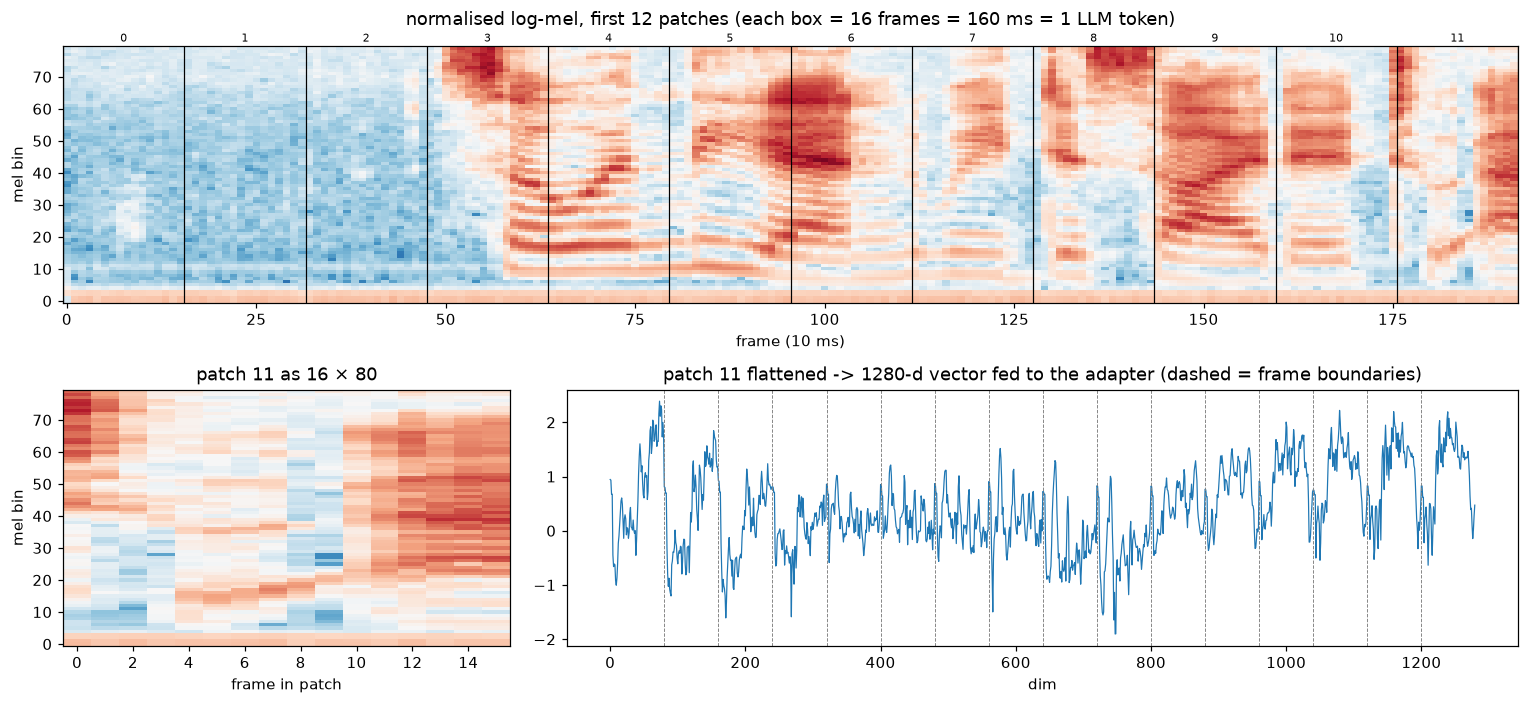

In [12]:
# Zoom into the first 2 seconds and draw the patch boundaries
n_show = min(len(patches), max(1, round(2 * FPS / T.STACK)))   # patches in 2 s
fig = plt.figure(figsize=(14, 6.5))
ax = fig.add_subplot(2, 1, 1)
ax.imshow(padded[: n_show * T.STACK].T, origin="lower", aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3)
for k in range(n_show + 1):
    ax.axvline(k * T.STACK - 0.5, color="k", lw=0.8)
for k in range(0, n_show, max(1, n_show // 40)):
    ax.text(k * T.STACK + (T.STACK - 1) / 2, T.N_MELS + 1, str(k), ha="center", fontsize=7)
ax.set(xlabel=f"frame ({1000 / FPS:.0f} ms)", ylabel="mel bin")
ax.set_title(f"normalised log-mel, first {n_show} patches "
             f"(each box = {T.STACK} frames = {1000 * T.STACK / FPS:.0f} ms = 1 LLM token)", pad=14)

k = min(12, n_show - 1)
ax = fig.add_subplot(2, 3, 4)
ax.imshow(patches[k].view(T.STACK, T.N_MELS).T, origin="lower", aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3)
ax.set(title=f"patch {k} as {T.STACK} × {T.N_MELS}", xlabel="frame in patch", ylabel="mel bin")
ax = fig.add_subplot(2, 3, (5, 6))
ax.plot(patches[k], lw=0.8)
for f in range(1, T.STACK):
    ax.axvline(f * T.N_MELS, color="gray", lw=0.6, ls="--")
ax.set(title=f"patch {k} flattened -> {PATCH_DIM}-d vector fed to the adapter (dashed = frame boundaries)", xlabel="dim")
plt.tight_layout(); plt.show()


## 4. The adapter: audio patch → LLM token

The whole "audio encoder" is **one `nn.Linear(STACK * N_MELS → hidden_size)`**, trained from a random init together
with LoRA (`T.load_model_and_projector()`; its dtype follows `PRECISION`: bf16 by default, fp32 for older runs):

```
patch (STACK·N_MELS) ──► W (hidden × STACK·N_MELS) · patch + b ──► audio token embedding (hidden), same space as text token embeddings
```

No conv, no attention, no non-linearity: all contextual modelling across patches is left to the LLM. That is why the
LLM has to be adapted too: it is frozen, and LoRA (`LORA_R=64`, `LORA_ALPHA=128`) is added to the LLM's linear layers
selected by `LORA_TARGETS` (default `"all-linear"`). On the hybrid LFM2 stack that is:

| block | layers (230M: 14) | LoRA on |
|---|---|---|
| short-conv blocks | 8 | `in_proj`, `out_proj` |
| attention blocks | 6 | `q_proj`, `k_proj`, `v_proj`, `out_proj` |
| MLP (every block) | 14 | `w1`, `w2`, `w3` |
| embeddings, `lm_head` | | none (frozen) |

`--lora_targets q_proj,k_proj,v_proj,out_proj` restricts it (e.g. attention only); section 6 prints the actual placement
via `T.describe_lora_placement()`, the same line `train.py` logs at startup.


In [13]:
cfg = AutoConfig.from_pretrained(T.MODEL)
adapter = torch.nn.Linear(PATCH_DIM, H)
print(adapter)
print(f"weight {tuple(adapter.weight.shape)} + bias {tuple(adapter.bias.shape)} = {sum(p.numel() for p in adapter.parameters()):,} params")
print(f"LLM {T.MODEL}: hidden_size={H}, layers={cfg.num_hidden_layers}, vocab={cfg.vocab_size}")

proj_path = RUN_DIR / "proj.pt" if RUN_DIR else None
TRAINED = proj_path is not None
if TRAINED:
    adapter.load_state_dict(torch.load(proj_path, map_location="cpu"))
    print("loaded trained adapter from", proj_path)
else:
    print("no trained checkpoint found: showing the random init")

with torch.no_grad():
    audio_tokens = adapter(patches)
print(f"\npatches {tuple(patches.shape)} --adapter--> audio tokens {tuple(audio_tokens.shape)}  "
      f"({sample['sec']:.2f} s of audio = {audio_tokens.shape[0]} LLM tokens)")

Linear(in_features=1280, out_features=1024, bias=True)
weight (1024, 1280) + bias (1024,) = 1,311,744 params
LLM LiquidAI/LFM2.5-230M-Base: hidden_size=1024, layers=14, vocab=65536
loaded trained adapter from runs/20261027-142314_fix_matchemb_plr10_ponly300_smoke1500/proj.pt

patches (98, 1280) --adapter--> audio tokens (98, 1024)  (15.61 s of audio = 98 LLM tokens)


### Patch size vs LLM width

With the paper's `STACK=8` a patch has **640 numbers but becomes a 1024-d token** (230M): the adapter *widens* its input, so
`W` has rank ≤ 640 and every audio token lives in a 640-d (affine) subspace of the embedding space. A linear map cannot add
information, so ~40% of each token's width carries nothing new; the LLM spends a full sequence position on 80 ms of audio.

That is why the default here is `STACK=16` (1280-d ≥ 1024). Larger patches (`STACK` ↑) put more audio into each token and make the sequence shorter (attention and decode get
cheaper, `PATCH_DIM ≥ hidden_size` lets the projection use the full width). The cost is time resolution: the adapter
has to compress more speech per token linearly, and the audio token rate drifts toward the text token rate.
The table below shows the trade-off for the current `MODEL` / `N_MELS` (`audio/text` = audio tokens per transcript token
on train-clean-100; it should stay well above 1). Try a value with `OVERRIDES = {"STACK": ...}` and
`python train.py --stack ...`.


text: 3.15 tokens/s of speech (incl. EOS), mean 40 tokens/utt | MODEL hidden_size H = 1024

 STACK  patch  dim/H     Hz  ms/tok  audio tok  seq len  audio/text   adapter
     4    320   0.31  25.00      40        316      359        8.08     0.33M
     6    480   0.47  16.67      60        211      254        5.39     0.49M
     8    640   0.62  12.50      80        158      201        4.05     0.66M
    10    800   0.78  10.00     100        127      170        3.24     0.82M
    12    960   0.94   8.33     120        106      149        2.70     0.98M
    16   1280   1.25   6.25     160         79      122        2.03     1.31M  <- current
    20   1600   1.56   5.00     200         64      107        1.63     1.64M
    24   1920   1.88   4.17     240         53       96        1.36     1.97M
    32   2560   2.50   3.12     320         40       83        1.02     2.62M


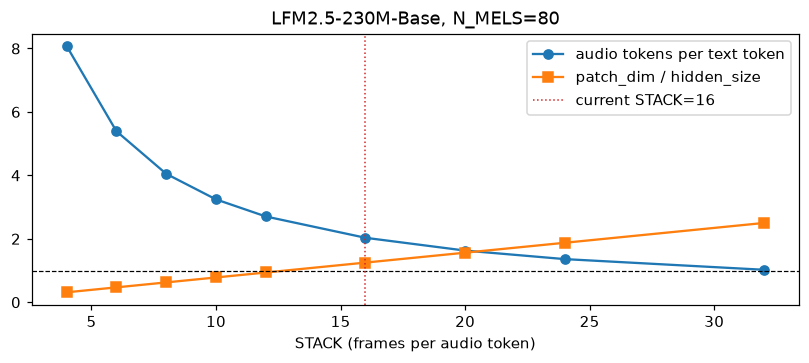

In [14]:
sweep_items = random.Random(0).sample(train_items, min(2000, len(train_items)))
sweep_sec = np.array([it["sec"] for it in sweep_items])
sweep_text = np.array([len(tok(" " + it["text"], add_special_tokens=False).input_ids) + 1 for it in sweep_items])
print(f"text: {sweep_text.sum() / sweep_sec.sum():.2f} tokens/s of speech (incl. EOS), "
      f"mean {sweep_text.mean():.0f} tokens/utt | MODEL hidden_size H = {H}\n")

rows = []
for s in sorted(set(STACK_SWEEP) | {T.STACK}):
    audio_tok = np.ceil(sweep_sec * FPS / s)
    d = s * T.N_MELS
    rows.append(dict(stack=s, patch_dim=d, dim_over_H=d / H, rate_hz=FPS / s, ms_per_tok=1000 * s / FPS,
                     audio_tok=audio_tok.mean(), seq_len=(1 + audio_tok + 2 + sweep_text).mean(),
                     audio_per_text=(audio_tok / sweep_text).mean(), adapter_params=d * H + H))

print(f"{'STACK':>6}{'patch':>7}{'dim/H':>7}{'Hz':>7}{'ms/tok':>8}{'audio tok':>11}{'seq len':>9}{'audio/text':>12}{'adapter':>10}")
for r in rows:
    mark = "  <- current" if r["stack"] == T.STACK else ""
    print(f"{r['stack']:>6}{r['patch_dim']:>7}{r['dim_over_H']:>7.2f}{r['rate_hz']:>7.2f}{r['ms_per_tok']:>8.0f}"
          f"{r['audio_tok']:>11.0f}{r['seq_len']:>9.0f}{r['audio_per_text']:>12.2f}{r['adapter_params'] / 1e6:>9.2f}M{mark}")

fig, ax = plt.subplots(figsize=(9, 3.2))
st = [r["stack"] for r in rows]
ax.plot(st, [r["audio_per_text"] for r in rows], "o-", label="audio tokens per text token")
ax.plot(st, [r["dim_over_H"] for r in rows], "s-", label="patch_dim / hidden_size")
ax.axhline(1, color="k", lw=0.8, ls="--")
ax.axvline(T.STACK, color="C3", lw=1, ls=":", label=f"current STACK={T.STACK}")
ax.set(xlabel="STACK (frames per audio token)", title=f"{T.MODEL.split('/')[-1]}, N_MELS={T.N_MELS}")
ax.legend(); plt.show()


### 4b. Front-end sweep: `SR`, `N_FFT`, `HOP`, `N_MELS`, `STACK` side by side

Edit `FRONTEND_SWEEP` in section 0 (each entry overrides some of the five knobs; `MVN_N` stays fixed) and re-run from here.
Every config is measured on the same `FRONTEND_PROBE_N` train utterances, without training anything:

| column | what it measures | good direction |
|---|---|---|
| `win ms` / `Hz/bin` | STFT window length (time blur) and FFT bin spacing (frequency detail), set by `N_FFT / SR` | trade-off |
| `fps` / `tok Hz` / `ms/tok` | mel frames per second (`SR/HOP`) and audio tokens per second (`SR/HOP/STACK`) | trade-off |
| `dead` | mel filters that cover **no FFT bin** (`N_MELS` too high for `N_FFT`): constant inputs, wasted patch dims | 0 |
| `LSD dB` | log-spectral distance between a fine 16 kHz reference spectrum (512-pt, 4 ms hop) and what survives the log-mel, mapped back to that grid. Measures **information lost by `SR / N_FFT / HOP / N_MELS`** (`STACK` is a lossless reshape, so it doesn't change it) | lower |
| `patch` / `dim/H` | adapter input size and its ratio to the LLM width (< 1: the linear adapter can only fill a `patch`-d subspace) | ≥ 1 |
| `PC95` / `PC99` / `PC99/H` | principal components holding 95 % / 99 % of the variance of the normalised patches: how many dims the patch *really* uses | ≤ H is enough |
| `audio/text` | audio tokens per transcript token (must stay well above 1, the model emits ≤ 1 text token per audio token of context) | ≳ 2 |
| `seq len` / `LLM cost` | mean `[BOS][audio][prompt][text][EOS]` length, and its ratio to the current config (≈ training/decode compute) | lower |

These are **proxies**: they tell you what each knob costs and what it throws away, not the WER. A config is only "good"
once it is trained; the cell after the plots prints the `train.py` command for each one.


In [ ]:
import soxr
import torch.nn.functional as F

FE_KEYS = ["SR", "N_FFT", "HOP", "N_MELS", "STACK"]
BASE = {k: getattr(T, k) for k in FE_KEYS}
SRC_SR = 16000                                                         # LibriSpeech
probe = random.Random(1).sample(train_items, min(FRONTEND_PROBE_N, len(train_items)))
probe_wavs = [sf.read(it["path"], dtype="float32")[0] for it in probe]

def power_per_hz(power, n_fft, sr):
    # |X|^2 / sum(w^2) / sr = power spectral density: comparable across window lengths and sample rates
    return power / (torch.hann_window(n_fft) ** 2).sum() / sr

REF_FFT, REF_HOP = 512, 64                                             # 31 Hz x 4 ms reference grid at 16 kHz
REF_FREQS = np.fft.rfftfreq(REF_FFT, 1 / SRC_SR)
ref_db = [10 * torch.log10(power_per_hz(torch.stft(torch.from_numpy(w), REF_FFT, REF_HOP, window=torch.hann_window(REF_FFT),
                                                   return_complex=True).abs() ** 2, REF_FFT, SRC_SR) + 1e-20)
          for w in probe_wavs]

def mel_to_linear(log_mel):
    """(frames, N_MELS) log-mel -> (N_FFT/2+1, frames) power: each FFT bin gets the filter-weighted average of the
    mean power per filter (i.e. assumes a flat spectrum inside each filter); bins no filter covers get ~0."""
    fb = T.MEL_FILTERBANK
    per_filter = torch.exp(log_mel).T / fb.sum(1, keepdim=True).clamp_min(1e-8)
    return fb.T @ per_filter / fb.sum(0)[:, None].clamp_min(1e-8)

def log_spectral_distance(log_mel, ref, floor_db=80):
    """RMS dB error (per frame, then averaged) of the log-mel mapped back onto the reference grid. Above the config's
    Nyquist there is no information, so those bins are filled with the utterance's mean reference level."""
    rec = 10 * torch.log10(power_per_hz(mel_to_linear(log_mel), T.N_FFT, T.SR) + 1e-20)
    freqs = np.fft.rfftfreq(T.N_FFT, 1 / T.SR)
    n_ref = int((REF_FREQS <= min(T.SR, SRC_SR) / 2).sum())
    rec = F.interpolate(rec[freqs <= SRC_SR / 2][None, None], size=(n_ref, ref.shape[1]), mode="bilinear",
                        align_corners=True)[0, 0]
    rec = torch.cat([rec, ref.mean().expand(ref.shape[0] - n_ref, ref.shape[1])])
    lo = ref.max() - floor_db                                         # ignore detail more than 80 dB below the peak
    return (rec.clamp_min(lo) - ref.clamp_min(lo)).pow(2).mean(0).sqrt().mean().item()

def griffin_lim(power, n_iter=32):
    """Phase-less (N_FFT/2+1, frames) power -> waveform at T.SR, to *hear* what the features keep."""
    win, mag = torch.hann_window(T.N_FFT), power.sqrt()
    length = (mag.shape[1] - 1) * T.HOP
    phase = torch.exp(2j * np.pi * torch.rand(mag.shape, generator=torch.Generator().manual_seed(0)))
    for _ in range(n_iter):
        y = torch.istft(mag * phase, T.N_FFT, T.HOP, window=win, length=length)
        phase = torch.exp(1j * torch.stft(y, T.N_FFT, T.HOP, window=win, return_complex=True).angle())
    return torch.istft(mag * phase, T.N_FFT, T.HOP, window=win, length=length).numpy()

def label(cfg):
    return ", ".join(f"{k}={v}" for k, v in cfg.items()) or "current"

fe_rows, fe_views = [], []
try:
    for cfg in FRONTEND_SWEEP:
        T.apply_config({**BASE, **cfg})
        fps = T.SR / T.HOP
        wavs = probe_wavs if T.SR == SRC_SR else [soxr.resample(w, SRC_SR, T.SR).astype(np.float32) for w in probe_wavs]
        mels = [T.log_mel_from_waveform(w) for w in wavs]
        cat = torch.cat(mels)
        mean, std = cat.mean(0), cat.std(0).clamp_min(1e-5)           # MVN from the probe set (cache untouched)
        patches = torch.cat([F.pad((m - mean) / std, (0, 0, 0, (-len(m)) % T.STACK)).reshape(-1, T.STACK * T.N_MELS)
                             for m in mels])
        var = torch.linalg.svdvals(patches - patches.mean(0)) ** 2
        pc95, pc99 = (int((var.cumsum(0) / var.sum() < q).sum()) + 1 for q in (0.95, 0.99))
        audio_tok = np.ceil(sweep_sec * fps / T.STACK)
        seq_len = (1 + audio_tok + 2 + sweep_text).mean()
        fe_rows.append(dict(
            label=label(cfg), cfg=cfg, win_ms=1000 * T.N_FFT / T.SR, hz_bin=T.SR / T.N_FFT, fps=fps,
            tok_hz=fps / T.STACK, ms_tok=1000 * T.STACK / fps,
            dead=int(((T.MEL_FILTERBANK > 0).sum(1) == 0).sum()),
            lsd=np.mean([log_spectral_distance(m, r) for m, r in zip(mels, ref_db)]),
            patch=T.STACK * T.N_MELS, pc95=pc95, pc99=pc99, audio_text=(audio_tok / sweep_text).mean(), seq_len=seq_len))

        # the walk-through sample (section 1) under this config: normalised log-mel + Griffin-Lim resynthesis
        w = wav if T.SR == SRC_SR else soxr.resample(wav, SRC_SR, T.SR).astype(np.float32)
        m = T.log_mel_from_waveform(w)
        fe_views.append(dict(norm=(m - mean) / std, fps=fps, stack=T.STACK, n_mels=T.N_MELS, sr=T.SR,
                             audio=griffin_lim(mel_to_linear(m[: int(6 * fps)]))))
finally:
    T.apply_config(BASE)                                              # back to the notebook's config

base_len = next((r["seq_len"] for r in fe_rows if not r["cfg"]), fe_rows[0]["seq_len"])
print(f"{FRONTEND_PROBE_N} probe utterances | LLM {T.MODEL.split('/')[-1]}: H = {H}\n")
print(f"{'config':<34}{'win ms':>7}{'Hz/bin':>7}{'fps':>5}{'tok Hz':>7}{'ms/tok':>7}{'dead':>5}{'LSD dB':>7}"
      f"{'patch':>6}{'dim/H':>6}{'PC95':>6}{'PC99':>6}{'PC99/H':>7}{'audio/text':>11}{'seq len':>8}{'LLM cost':>9}")
for r in fe_rows:
    print(f"{r['label']:<34}{r['win_ms']:>7.0f}{r['hz_bin']:>7.0f}{r['fps']:>5.0f}{r['tok_hz']:>7.2f}{r['ms_tok']:>7.0f}"
          f"{r['dead']:>5}{r['lsd']:>7.2f}{r['patch']:>6}{r['patch'] / H:>6.2f}{r['pc95']:>6}{r['pc99']:>6}{r['pc99'] / H:>7.2f}"
          f"{r['audio_text']:>11.2f}{r['seq_len']:>8.0f}{r['seq_len'] / base_len:>8.2f}x")


In [ ]:
# Same 3 s of the walk-through sample under every config: what the adapter sees (black lines = token boundaries)
n = len(fe_views)
fig, axes = plt.subplots(n, 1, figsize=(13, 1.6 * n), sharex=True)
for ax, v, r in zip(np.atleast_1d(axes), fe_views, fe_rows):
    x = v["norm"][: int(3 * v["fps"])]
    ax.imshow(x.T, origin="lower", aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3, extent=[0, len(x) / v["fps"], 0, v["n_mels"]])
    for t in np.arange(0, len(x), v["stack"]) / v["fps"]:
        ax.axvline(t, color="k", lw=0.4)
    ax.set_ylabel("mel bin", fontsize=8)
    ax.set_title(f"{r['label']}  |  {v['n_mels']} mels to {v['sr'] // 2} Hz, {r['fps']:.0f} fps, "
                 f"{r['tok_hz']:.2f} tokens/s, LSD {r['lsd']:.1f} dB", fontsize=9, loc="left")
axes[-1].set_xlabel("time (s)")
plt.tight_layout(); plt.show()

# Summary: what each config loses (LSD), how much it asks of the LLM (cost, audio/text) and how it fills the width
fig, axes = plt.subplots(1, 4, figsize=(15, 0.45 * n + 1.5), sharey=True)
y = np.arange(n)
for ax, (key, title, ref) in zip(axes, [
        ("lsd", "LSD vs 16 kHz reference (dB, lower = keeps more)", None),
        ("audio_text", "audio tokens per text token", 1),
        (lambda r: r["seq_len"] / base_len, "LLM cost vs current (x)", 1),
        (lambda r: r["pc99"] / H, "PC99 / hidden size", 1)]):
    vals = [key(r) if callable(key) else r[key] for r in fe_rows]
    ax.barh(y, vals, color=["C3" if not r["cfg"] else "C0" for r in fe_rows])
    if ref is not None:
        ax.axvline(ref, color="k", lw=0.8, ls="--")
    ax.set_title(title, fontsize=9)
axes[0].set_yticks(y, [r["label"] for r in fe_rows], fontsize=8); axes[0].invert_yaxis()
plt.tight_layout(); plt.show()


In [ ]:
# Listen: Griffin-Lim resynthesis of the first 6 s from each config's log-mel (no phase, so it sounds robotic in every
# config; compare intelligibility and muffling between them, e.g. SR=8000 loses the "s"/"f" hiss, N_MELS=40 blurs vowels)
print("original"); display(Audio(wav[: 6 * SRC_SR], rate=SRC_SR))
for v, r in zip(fe_views, fe_rows):
    print(r["label"]); display(Audio(v["audio"], rate=v["sr"]))

print("\nTrain a config (then compare val / test WER in runs/INDEX.md):")
for r in fe_rows:
    flags = " ".join(f"--{k.lower()} {v}" for k, v in r["cfg"].items())
    note = "   # not trainable yet: train.py asserts file SR == SR (LibriSpeech is 16 kHz, no resampling)" \
           if r["cfg"].get("SR", SRC_SR) != SRC_SR else ""
    print(f"  python train.py {flags}".rstrip() + note)


**Reading the sweep.** Each knob moves the proxies in a predictable way:

* **`STACK`** loses nothing (same LSD), it only trades sequence length (cost, `audio/text`) against how much speech
  one token and the adapter have to summarise. Keep `audio/text` comfortably above ~2 and `patch ≳ H`.
* **`N_MELS`** ↑ lowers LSD (finer formants/pitch harmonics) but grows the patch; check `dead` stays 0 (with
  `N_FFT=400` the lowest filters start to be empty around 128+ mels, then raise `N_FFT` too). `PC95` shows whether the
  extra dims carry anything new.
* **`N_FFT`** ↑ sharpens frequency (`Hz/bin`) but blurs fast events (`win ms`); ↓ the opposite. 20–32 ms is the usual range.
* **`HOP`** ↑ halves the frame rate: cheaper at a fixed `STACK`, or the same token rate with a smaller `STACK`; but
  plosives/short phones get smeared (LSD ↑). Keep `N_FFT ≥ HOP` (ideally ~2.5x) so no audio falls between windows.
* **`SR`** below 16 kHz removes the band above `SR/2` (fricatives); above 16 kHz adds nothing for LibriSpeech (it is
  16 kHz audio) and only spends mel bins on an empty band. Note `train.extract_log_mel_spectrogram` asserts the file
  rate equals `SR`, so training at another `SR` needs a resampling step there first (the sweep resamples with soxr).

To retrain on a front-end, run its printed command; then set `OVERRIDES` in section 0 to the same values to walk the
rest of this notebook through it (that also builds and caches its full `MVN_N` stats in section 3c).


### What did the trained adapter learn?
Reshape `W` from `(hidden, STACK·N_MELS)` to `(hidden, STACK frames, N_MELS bins)`: the column norms show how much each
(frame-in-patch, mel bin) input contributes to the output embedding. The singular values show how much of the
`min(STACK·N_MELS, hidden)` possible rank the adapter actually uses.


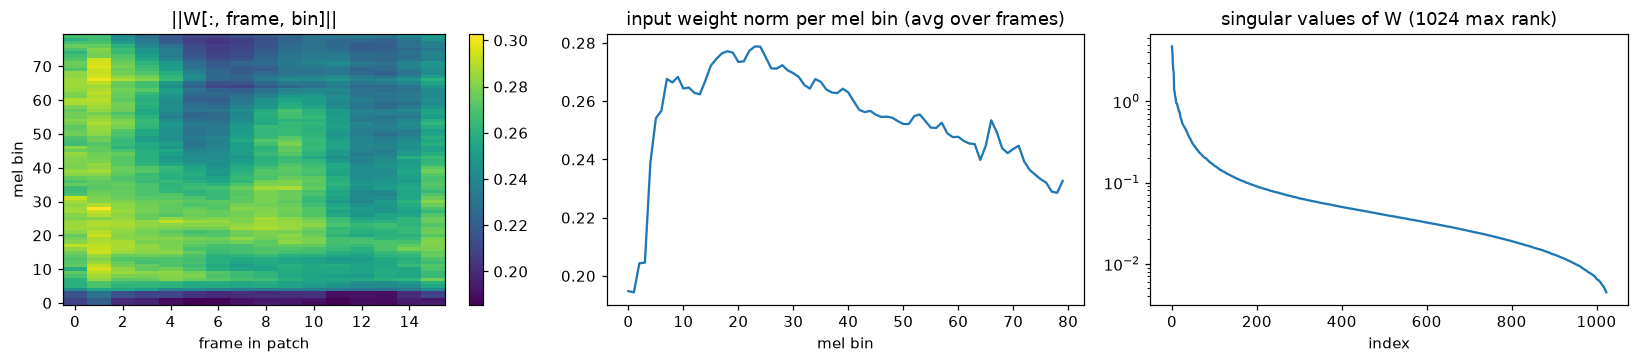

effective rank (singular values > 1% of max): 427 / 1024


In [15]:
W = adapter.weight.detach().view(H, T.STACK, T.N_MELS)
col_norm = W.norm(dim=0)                         # (8, 80)
s = torch.linalg.svdvals(adapter.weight.detach())

fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
im = axes[0].imshow(col_norm.T, origin="lower", aspect="auto", cmap="viridis")
axes[0].set(title="||W[:, frame, bin]||", xlabel="frame in patch", ylabel="mel bin"); plt.colorbar(im, ax=axes[0])
axes[1].plot(col_norm.mean(0)); axes[1].set(title="input weight norm per mel bin (avg over frames)", xlabel="mel bin")
axes[2].semilogy(s.numpy()); axes[2].set(title=f"singular values of W ({min(W.shape[0], PATCH_DIM)} max rank)", xlabel="index")
plt.tight_layout(); plt.show()
print(f"effective rank (singular values > 1% of max): {(s > 0.01 * s[0]).sum().item()} / {len(s)}")

### Do audio tokens live where text tokens live?
Compare the norms of the projected audio tokens with the LLM's text token embeddings (loaded straight from the
checkpoint's safetensors, without loading the whole model).

text embedding matrix (65536, 1024)


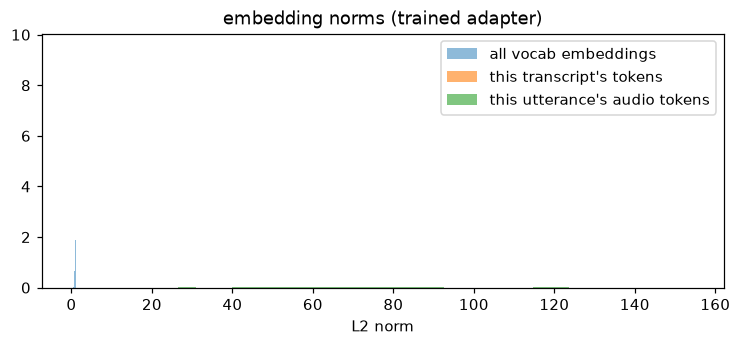

audio tokens: 98 for 15.6 s | text tokens: 69 | ratio 1.4 audio tokens per text token


In [16]:
from huggingface_hub import hf_hub_download
from safetensors import safe_open
import glob

model_dir = Path(hf_hub_download(T.MODEL, "config.json")).parent
emb = None
for f in glob.glob(str(model_dir / "*.safetensors")):
    with safe_open(f, "pt") as st:
        for key in st.keys():
            if "embed_tokens" in key:
                emb = st.get_tensor(key).float()
print("text embedding matrix", tuple(emb.shape))

text_ids = tok(" " + sample["text"], add_special_tokens=False).input_ids
text_norms = emb[text_ids].norm(dim=1)
audio_norms = audio_tokens.norm(dim=1)
plt.figure(figsize=(8, 3))
plt.hist(emb.norm(dim=1).numpy(), bins=80, alpha=0.5, density=True, label="all vocab embeddings")
plt.hist(text_norms.numpy(), bins=30, alpha=0.6, density=True, label="this transcript's tokens")
plt.hist(audio_norms.numpy(), bins=30, alpha=0.6, density=True, label="this utterance's audio tokens")
plt.xlabel("L2 norm"); plt.legend(); plt.title("embedding norms" + (" (trained adapter)" if TRAINED else " (random adapter)")); plt.show()
print(f"audio tokens: {len(audio_norms)} for {sample['sec']:.1f} s | text tokens: {len(text_ids)} "
      f"| ratio {len(audio_norms) / len(text_ids):.1f} audio tokens per text token")

## 5. The final input sequence

`T.build_multimodal_inputs()` builds `inputs_embeds` directly (no token ids for audio):

```
[BOS] [audio_0 … audio_N-1] [“Transcription:”] [ text tokens … ] [EOS]
  └────────── labels = -100 (no loss) ──────────┘ └── loss here ────┘
```

* **train**: right-padded with the pad-token embedding, labels `-100` on BOS/audio/prompt/pad
* **generate**: no target, **left-padded** so every row ends at the prompt and generation continues from there

In [17]:
ds = T.SpeechDataset(train_items, mvn, tok)
# A real bucketed batch has near-identical lengths (almost no padding). To make padding visible,
# take 3 utterances of clearly different lengths (~4 s, ~9 s, ~14 s) instead.
pick = [min(range(len(train_items)), key=lambda i: abs(train_items[i]["sec"] - s)) for s in (4, 9, 14)]
batch = [ds[i] for i in pick]
prompt_ids = tok(T.PROMPT, add_special_tokens=False).input_ids
print("prompt", repr(T.PROMPT), "->", prompt_ids, [tok.decode([i]) for i in prompt_ids])
print("BOS", tok.bos_token_id, repr(tok.bos_token), "| EOS", tok.eos_token_id, repr(tok.eos_token),
      "| PAD", tok.pad_token_id, repr(tok.pad_token))
print("target of item 0:", batch[0]["target"][:12], "...", [tok.decode([i]) for i in batch[0]["target"][:8]], "...")

class EmbOnly(torch.nn.Module):
    # build_multimodal_inputs only calls model.get_input_embeddings(); avoid loading the full LLM here
    def __init__(self, w): super().__init__(); self.e = torch.nn.Embedding.from_pretrained(w)
    def get_input_embeddings(self): return self.e

emb_model = EmbOnly(emb)
# This illustration uses the CPU fp32 embedding table + adapter from above (exact checks in the next cell);
# build_multimodal_inputs reads T.DEVICE / T.DTYPE, so switch them to CPU fp32 just for these two calls.
_device, _dtype = T.DEVICE, T.DTYPE
T.DEVICE, T.DTYPE = "cpu", torch.float32
try:
    x_tr, m_tr, y_tr = T.build_multimodal_inputs(batch, emb_model, adapter, tok, prompt_ids, is_train=True)
    x_ge, m_ge, _ = T.build_multimodal_inputs(batch, emb_model, adapter, tok, prompt_ids, is_train=False)
finally:
    T.DEVICE, T.DTYPE = _device, _dtype
print(f"\ntrain : inputs_embeds {tuple(x_tr.shape)}, attention_mask {tuple(m_tr.shape)}, labels {tuple(y_tr.shape)}")
print(f"decode: inputs_embeds {tuple(x_ge.shape)}")
for it, row in zip(batch, m_tr):
    print(f"  {it['id']}: 1 BOS + {it['audio'].shape[0]} audio + {len(prompt_ids)} prompt + {len(it['target'])} target"
          f" = {int(row.sum())}  (pad {row.numel() - int(row.sum())})")

prompt 'Transcription:' -> [7478, 34180, 535] ['Trans', 'cription', ':']
BOS 1 '<|startoftext|>' | EOS 7 '<|im_end|>' | PAD 0 '<|pad|>'
target of item 0: [1403, 779, 12640, 28504, 1090, 9545, 46103, 810, 4925, 2681, 811, 1450] ... [' when', ' the', ' flower', ' queen', "'s", ' daughter', ' departed', ' and'] ...

train : inputs_embeds (3, 135, 1024), attention_mask (3, 135), labels (3, 135)
decode: inputs_embeds (3, 92, 1024)
  1898-145724-0036: 1 BOS + 25 audio + 3 prompt + 14 target = 43  (pad 92)
  1034-121119-0078: 1 BOS + 57 audio + 3 prompt + 32 target = 93  (pad 42)
  150-126112-0018: 1 BOS + 88 audio + 3 prompt + 43 target = 135  (pad 0)


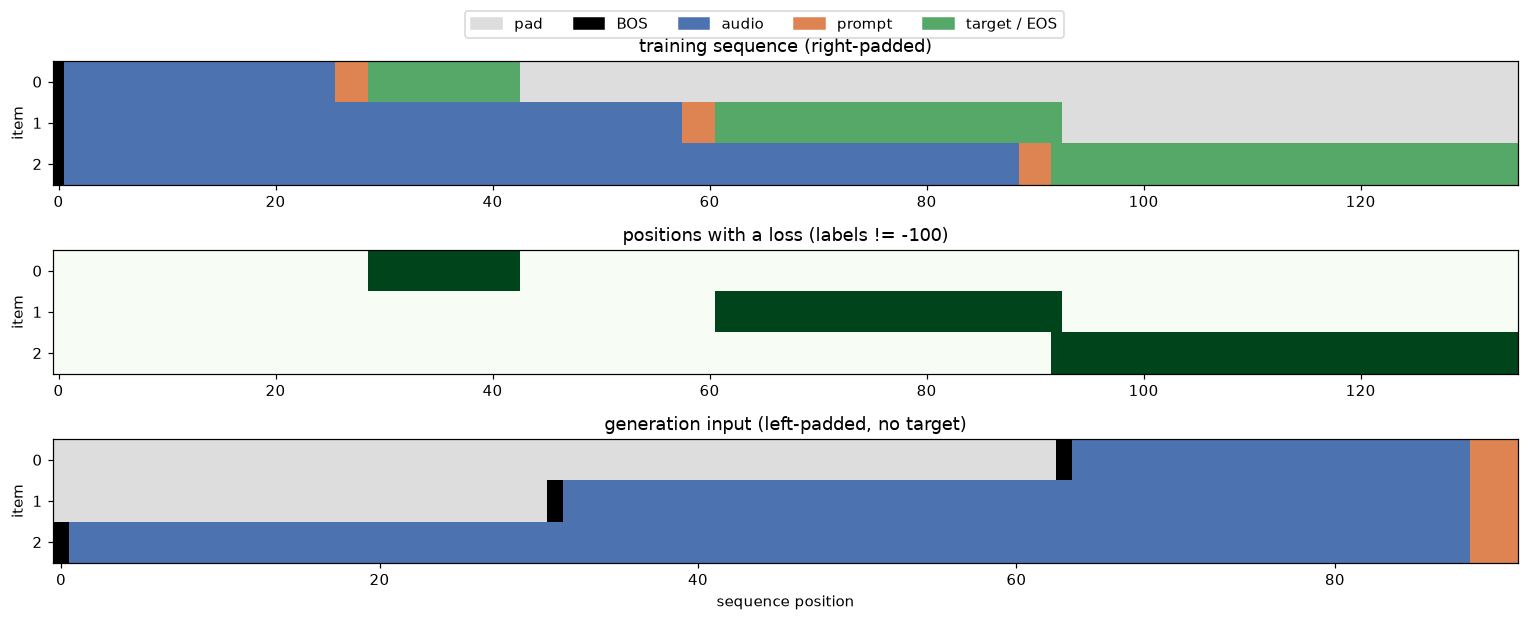

row 0 checks passed: BOS / audio / prompt embeddings are where expected


In [18]:
from matplotlib.colors import ListedColormap
KIND = ["pad", "BOS", "audio", "prompt", "target / EOS"]
cmap = ListedColormap(["#dddddd", "#000000", "#4c72b0", "#dd8452", "#55a868"])

def layout(batch, n_cols, left):
    grid = np.zeros((len(batch), n_cols), dtype=int)
    for r, it in enumerate(batch):
        seg = [1] + [2] * it["audio"].shape[0] + [3] * len(prompt_ids) + ([4] * len(it["target"]) if not left else [])
        start = n_cols - len(seg) if left else 0
        grid[r, start:start + len(seg)] = seg
    return grid

fig, axes = plt.subplots(3, 1, figsize=(14, 5.5), sharex=False)
axes[0].imshow(layout(batch, x_tr.shape[1], False), aspect="auto", cmap=cmap, vmin=0, vmax=4, interpolation="nearest")
axes[0].set_title("training sequence (right-padded)")
axes[1].imshow((y_tr != -100).numpy(), aspect="auto", cmap="Greens", interpolation="nearest")
axes[1].set_title("positions with a loss (labels != -100)")
axes[2].imshow(layout(batch, x_ge.shape[1], True), aspect="auto", cmap=cmap, vmin=0, vmax=4, interpolation="nearest")
axes[2].set_title("generation input (left-padded, no target)")
for ax in axes: ax.set_yticks(range(len(batch))); ax.set_ylabel("item")
axes[2].set_xlabel("sequence position")
handles = [plt.Rectangle((0, 0), 1, 1, color=cmap(i)) for i in range(5)]
fig.legend(handles, KIND, loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.03))
plt.tight_layout(); plt.show()

# sanity: embedding rows match their sources
r = 0; n_a = batch[r]["audio"].shape[0]
assert torch.allclose(x_tr[r, 0], emb[tok.bos_token_id])
assert torch.allclose(x_tr[r, 1:1 + n_a], adapter(batch[r]["audio"]), atol=1e-5)
assert torch.allclose(x_tr[r, 1 + n_a:1 + n_a + len(prompt_ids)], emb[prompt_ids])
print("row 0 checks passed: BOS / audio / prompt embeddings are where expected")

## 6. (optional) Forward pass and greedy decode with the trained checkpoint

Loads the LLM + LoRA on `DEVICE` and prints where LoRA sits (230M: ~1 GB in bf16 on the GPU, a bit slow but fine on CPU). Only runs if a matching run was found (`RUN_DIR` in section 0).


In [19]:
RUN_LLM = TRAINED

if RUN_LLM:
    tok_, model, proj = T.load_model_and_projector(str(RUN_DIR))
    model.eval()
    print(T.describe_lora_placement(model))
    with torch.no_grad():
        x, m, y = T.build_multimodal_inputs(batch, model, proj, tok, prompt_ids, is_train=True)
        out = model(inputs_embeds=x, attention_mask=m, labels=y)
        print(f"teacher-forced loss on 3 items: {out.loss.item():.3f}  (logits {tuple(out.logits.shape)})")

        x, m, _ = T.build_multimodal_inputs(batch, model, proj, tok, prompt_ids, is_train=False)
        gen = model.generate(inputs_embeds=x, attention_mask=m, max_new_tokens=60, do_sample=False,
                             eos_token_id=tok.eos_token_id, pad_token_id=tok.pad_token_id)
    for it, g in zip(batch, gen):
        print(f"\n[{it['id']}]\nREF: {it['text']}\nHYP: {T.normalize_text_for_wer(tok.decode(g, skip_special_tokens=True))}")

Loading weights: 100%|██████████| 132/132 [00:00<00:00, 1278.16it/s]


lora on LLM ('all-linear', r64 a128 dropout 0.05): in_proj (8/14 layers), k_proj (6/14 layers), out_proj (14/14 layers), q_proj (6/14 layers), v_proj (6/14 layers), w1 (14/14 layers), w2 (14/14 layers), w3 (14/14 layers) | LLM base weights frozen, audio projector fully trained
teacher-forced loss on 3 items: 3.476  (logits (3, 135, 65536))

[1898-145724-0036]
REF: when the flower queen's daughter departed and went home to her mother
HYP: and the two men were in a state of great distress

[1034-121119-0078]
REF: and when it commands it strikes you will tell me that i am a living being and not a code a man and not a volume look at me madame
HYP: and the whole of the world was in the midst of the war and the whole of europe was in the midst of the war the whole of the world was in the midst of the war

[150-126112-0018]
REF: now for your own sake princess said he i cannot let you go to sleep you must sit and look at me else i shall not be able to keep up well i will do anything i can to o

## 7. Run tracking: finding runs and their plots

Every `python train.py` gets its own `runs/<YYYYmmdd-HHMMSS>_<model>_stack<N>[_<changed hparams>]/` folder, e.g.
`--epochs 10 --batch_size 16` → `..._stack16_epochs10_bs16`.

* `runs/latest` → symlink to the newest run (`python runs.py latest`, `python runs.py show latest`)
* `runs/INDEX.md` → every run, newest first: status/step, what it changed, best val, test and benchmark WER
* `runs/<id>/plots.png` → loss, grad norm vs clip, lr, val WER (+sub/del/ins), throughput, memory; redrawn every
  `PLOT_EVERY` steps and after each val (`python runs.py plot <run>` for older runs)
* after training, `train.py` runs `benchmark.py` on all Open ASR sets (`BENCHMARK_SETS`) and stores the WERs in
  `runs/<id>/summary.json` under `benchmark`


latest run: runs/20261027-150147_mix544h_conv_stack8


# Runs (newest first; regenerated by train.py, `python runs.py` for the full table)

| run | status | model | changed vs defaults | best val WER | test-clean / other | benchmark avg | notes |
|---|---|---|---|---|---|---|---|
| [20261027-150147_mix544h_conv_stack8](20261027-150147_mix544h_conv_stack8/) | done | LFM2.5-230M-Base | stack=8, lr=0.0002, projector=conv, proj_lr_mult=2.5, warmup_steps=500, batch_size=16, grad_accum=2, precision=amp | 72.03 | 70.98 / 85.38 | 116.91 (7 sets) | 544h combined ASR train + Mel-LLM strided conv+MLP projector (12.5 Hz, unfold+GEMM) + independent grad clip + 9-set benchmark |
| [20261027-142314_fix_matchemb_plr10_ponly300_smoke1500](20261027-142314_fix_matchemb_plr10_ponly300_smoke1500/) | done | LFM2.5-230M-Base | proj_lr_mult=10, proj_only_steps=300, epochs=10, eval_every=250, precision=amp | 119.15 | - / - | - | projector-scale fix + proj lr x10 + 300 projector-only steps, 1500-step comparison |
| [20261027-141342_overfit10_matchemb](20261027-141342_overfit10_matchemb/) | running 130/300 | LFM2.5-230M-Base | val_n=10, test_splits=, train_n=10, val_from_train=True, lora_dropout=0, proj_lr_mult=10, warmup_steps=20, epochs=300, batch_size=10, grad_accum=1, grad_ckpt=False, eval_every=50, precision=fp32 | 0 | - / - | - | 10-utt overfit test, proj_init match_emb, fp32, proj lr x10 |
| [20261027-113038_LFM2.5-350M-Base_stack16_optmuon](20261027-113038_LFM2.5-350M-Base_stack16_optmuon/) | done | LFM2.5-350M-Base | model=LiquidAI/LFM2.5-350M-Base, optimizer=muon | 120.69 | 122.8 / 120.99 | 125.71 (3 sets) |  |
| [20261027-080057_LFM2.5-230M-Base_stack16_r32_ldrop0.5_lr1e-05_optmuon_epochs10_bs16](20261027-080057_LFM2.5-230M-Base_stack16_r32_ldrop0.5_lr1e-05_optmuon_epochs10_bs16/) | done | LFM2.5-230M-Base | lora_r=32, lora_dropout=0.5, lr=1e-05, optimizer=muon, epochs=10, batch_size=16 | 113.77 | 125.36 / 121.03 | 130.20 (7 sets) |  |
| [20261027-072544_LFM2.5-230M-Base_stack16_lr1e-05_epochs10_bs16](20261027-072544_LFM2.5-230M-Base_stack16_lr1e-05_epochs10_bs16/) | interrupted | LFM2.5-230M-Base | lr=1e-05, epochs=10, batch_size=16 | - | - / - | - |  |
| [20261027-005138_LFM2.5-230M-Base_stack16](20261027-005138_LFM2.5-230M-Base_stack16/) | done | LFM2.5-230M-Base | epochs=10, batch_size=16 | 122.26 | 117.64 / 115.82 | 123.56 (7 sets) |  |
| [20261027-005001_LFM2.5-230M-Base_stack16](20261027-005001_LFM2.5-230M-Base_stack16/) | interrupted | LFM2.5-230M-Base | epochs=10, batch_size=20 | - | - / - | - |  |
| [20261027-003051_LFM2.5-230M-Base_stack16](20261027-003051_LFM2.5-230M-Base_stack16/) | interrupted | LFM2.5-230M-Base | - | 104.92 | - / - | - |  |
| [baseline_fixed12.5hz](baseline_fixed12.5hz/) | done | LFM2.5-350M | - | 112.23 | 122.73 / 121.57 | 135.08 (7 sets) |  |


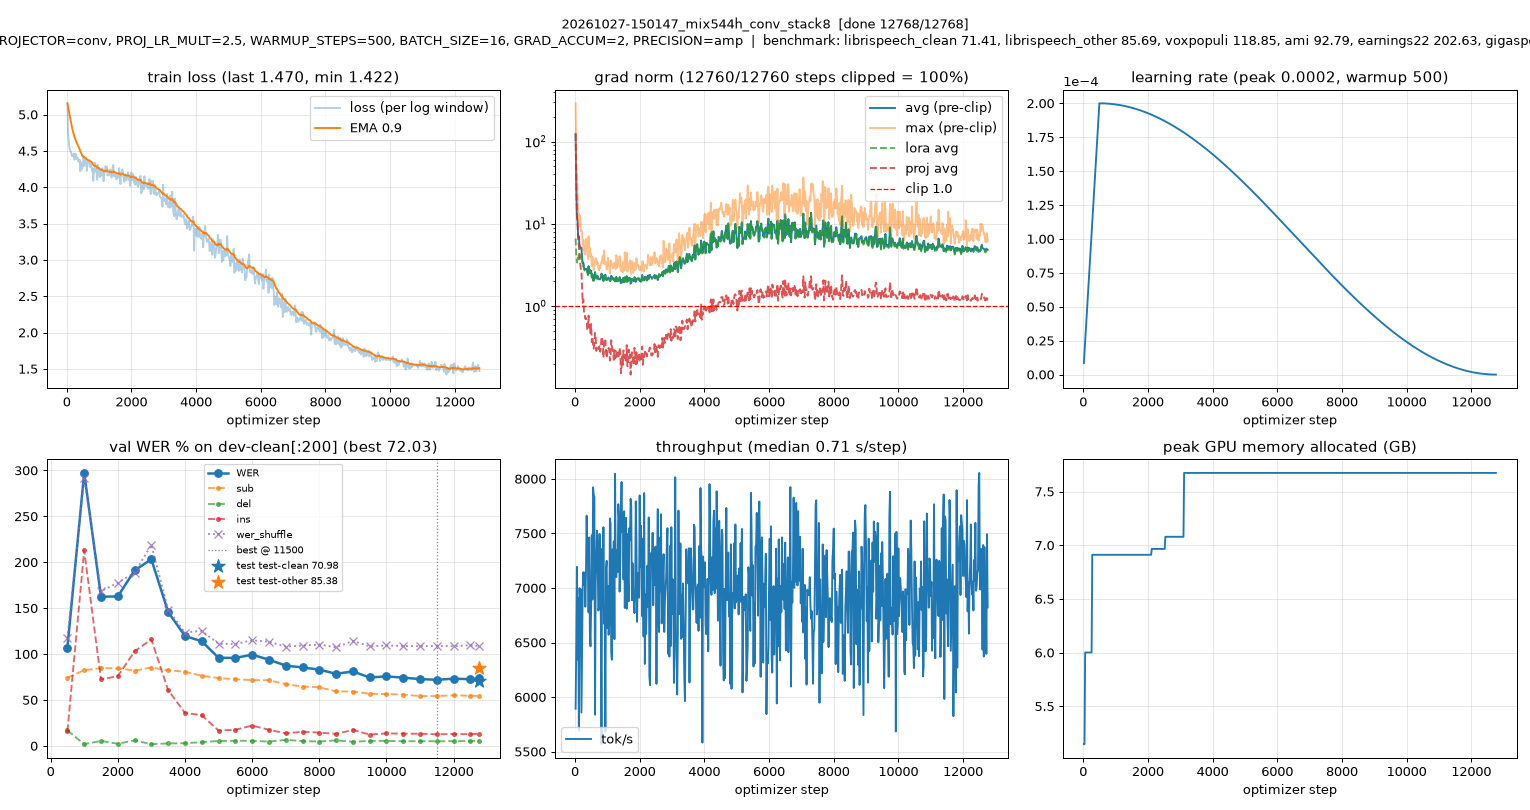

In [20]:
from IPython.display import Image, Markdown
import runs as R

latest = R.latest_run_dir()
print("latest run:", latest)
display(Markdown(Path("runs/INDEX.md").read_text() if Path("runs/INDEX.md").exists() else "no runs/INDEX.md yet"))
if latest is not None and R.plot_run(latest):   # (re)draw it now so it is current
    display(Image(filename=str(latest / "plots.png")))
